<a href="https://colab.research.google.com/github/Ravna95/Capstone-Project/blob/main/DataCo_Smart_Supply_Chain.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
#Step 1: Import Libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import f_oneway

sns.set_style("whitegrid")

print("Libraries imported successfully.")



Libraries imported successfully.


In [13]:
#Step 2: Load All 9 Datasets from GitHub

import pandas as pd

url = 'https://raw.githubusercontent.com/Ravna95/Capstone-Project/main/'
base_url = 'https://raw.githubusercontent.com/Ravna95/Capstone-Project/main/'

customers = pd.read_csv(base_url + "Customers.csv")
orders = pd.read_csv(base_url + "Orders.csv")
order_items = pd.read_csv(base_url + "Order%20Items.csv")
products = pd.read_csv(base_url + "Products.csv")
categories = pd.read_csv(base_url + "Categories.csv")
departments = pd.read_csv(base_url + "Departments.csv")
shipping = pd.read_csv(base_url + "Shipping.csv")
geography = pd.read_csv(base_url + "Geography.csv")
payment_types = pd.read_csv(base_url + "Payment%20Types.csv")

print("All datasets loaded successfully.")



All datasets loaded successfully.


In [15]:
#Step 3: Explore Dataset Sizes

datasets = {
    "Customers": customers,
    "Orders": orders,
    "Order Items": order_items,
    "Products": products,
    "Categories": categories,
    "Departments": departments,
    "Shipping": shipping,
    "Geography": geography,
    "Payment Types": payment_types
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")


Customers: (20652, 11)
Orders: (65752, 11)
Order Items: (180519, 15)
Products: (118, 7)
Categories: (51, 3)
Departments: (11, 2)
Shipping: (65752, 3)
Geography: (64990, 9)
Payment Types: (4, 2)


In [16]:
#Step 4: Check Column Names

for name, df in datasets.items():
    print("n" + "="*60)
    print(name)
    print("="*60)

    print(df.columns.tolist())

n============================================================
Customers
['Customer Id', 'Customer Fname', 'Customer Lname', 'Customer Email', 'Customer Password', 'Customer Segment', 'Customer Street', 'Customer City', 'Customer State', 'Customer Country', 'Customer Zipcode']
n============================================================
Orders
['Order Id', 'Order Customer Id', 'Payment_Type_ID', 'Shipment_Id', 'Location_Id', 'order date (DateOrders)', 'Order Status', 'Delivery Status', 'Late_delivery_risk', 'Days for shipping (real)', 'Days for shipment (scheduled)']
n============================================================
Order Items
['Order Item Id', 'Order Id', 'Order Item Cardprod Id', 'Product Card Id', 'Customer Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Order Item Total', 'Sales', 'Sales per customer', 'Benefit per order', 'Order Profit Per Order']
n==================================

In [17]:
#Step 5: Check Missing Values

for name, df in datasets.items():
    print("n" + "="*60)
    print(name)
    print("="*60)

    print(df.isnull().sum())

n============================================================
Customers
Customer Id          0
Customer Fname       0
Customer Lname       8
Customer Email       0
Customer Password    0
Customer Segment     0
Customer Street      0
Customer City        0
Customer State       0
Customer Country     0
Customer Zipcode     3
dtype: int64
n============================================================
Orders
Order Id                         0
Order Customer Id                0
Payment_Type_ID                  0
Shipment_Id                      0
Location_Id                      0
order date (DateOrders)          0
Order Status                     0
Delivery Status                  0
Late_delivery_risk               0
Days for shipping (real)         0
Days for shipment (scheduled)    0
dtype: int64
n============================================================
Order Items
Order Item Id               0
Order Id                    0
Order Item Cardprod Id      0
Product Card Id             0
C

In [18]:
#Step 6: Check Duplicate Records
for name, df in datasets.items():
    print(
        f"{name}: {df.duplicated().sum()} duplicate rows"
    )


Customers: 0 duplicate rows
Orders: 0 duplicate rows
Order Items: 0 duplicate rows
Products: 0 duplicate rows
Categories: 0 duplicate rows
Departments: 0 duplicate rows
Shipping: 0 duplicate rows
Geography: 0 duplicate rows
Payment Types: 0 duplicate rows


In [19]:
import numpy as np
import pandas as pd

print('Starting Step 7: Data Cleaning & Step 8: Feature Engineering...')

# ==========================================
# STEP 7: DATA CLEANING & PREPROCESSING
# ==========================================

# 7.1 Handle Missing Values in Products (Product Description is known to have nulls)
if 'Product Description' in products.columns:
  products['Product Description'] = products['Product Description'].fillna(
      'No Description Available'
  )

# 7.2 Convert Date Columns to Datetime Objects
# Orders dataset date
if 'order date (DateOrders)' in orders.columns:
  orders['order_date'] = pd.to_datetime(
      orders['order date (DateOrders)'], errors='coerce'
  )

# Shipping dataset date (if applicable)
if 'shipping date (DateOrders)' in shipping.columns:
  shipping['shipping_date'] = pd.to_datetime(
      shipping['shipping date (DateOrders)'], errors='coerce'
  )

print('Data cleaning completed: Dates parsed and missing descriptions handled.')

Starting Step 7: Data Cleaning & Step 8: Feature Engineering...
Data cleaning completed: Dates parsed and missing descriptions handled.


In [20]:
# ==========================================
# STEP 8: FEATURE ENGINEERING
# ==========================================

# 8.1 Merge core tables to create a unified master dataframe for analysis
df = order_items.merge(
    orders[
        [
            'Order Id',
            'Order Customer Id',
            'order_date',
            'Order Status',
            'Delivery Status',
            'Late_delivery_risk',
            'Days for shipping (real)',
            'Days for shipment (scheduled)',
        ]
    ],
    on='Order Id',
    how='left',
)

df = df.merge(
    products[['Product Card Id', 'Product Category Id', 'Product Name']],
    on='Product Card Id',
    how='left',
)

df = df.merge(
    categories[['Category Id', 'Category Name', 'Department Id']],
    left_on='Product Category Id',
    right_on='Category Id',
    how='left',
)

df = df.merge(departments, on='Department Id', how='left')

df = df.merge(
    customers[
        [
            'Customer Id',
            'Customer Segment',
            'Customer City',
            'Customer State',
            'Customer Country',
        ]
    ],
    on='Customer Id',
    how='left',
)

# 8.2 Extract Temporal Features
df['Year'] = df['order_date'].dt.year
df['Month'] = df['order_date'].dt.month
df['DayOfWeek'] = df['order_date'].dt.day_name()
df['YearMonth'] = df['order_date'].dt.to_period('M').astype(str)
df['Quarter'] = df['order_date'].dt.quarter

# 8.3 Feature Engineering: Supply Chain & Delivery Variance
# Difference between real shipping days and scheduled shipping days
df['Shipping_Delay_Variance'] = (
    df['Days for shipping (real)'] - df['Days for shipment (scheduled)']
)

# Binary flag for profit/loss per line item
df['Is_Profitable'] = df['Order Profit Per Order'].apply(
    lambda x: 1 if x > 0 else 0
)

print(
    'Feature engineering completed: Temporal, delivery variance, and profitability flags added.'
)
print(f'Master Analysis DataFrame Shape: {df.shape}')
print(df[['order_date', 'Year', 'Month', 'YearMonth', 'Shipping_Delay_Variance']].head(3))

Feature engineering completed: Temporal, delivery variance, and profitability flags added.
Master Analysis DataFrame Shape: (180519, 39)
           order_date  Year  Month YearMonth  Shipping_Delay_Variance
0 2018-01-31 22:56:00  2018      1   2018-01                       -1
1 2018-01-13 12:27:00  2018      1   2018-01                        1
2 2018-01-13 12:06:00  2018      1   2018-01                        0



OBJECTIVE 1: SALES PERFORMANCE METRICS
Total Gross Sales: $36,784,735.01
Total Net Revenue (Item Total): $33,054,402.38
Total Order Volume (Unique Orders): 65,752
Total Items Sold: 384,079

--- Yearly Sales Trends ---
   Year   Total_Sales  Total_Revenue  Order_Volume  Items_Sold
0  2015  1.234083e+07   1.108954e+07         20904      138480
1  2016  1.230382e+07   1.105600e+07         20859      137352
2  2017  1.180844e+07   1.061091e+07         21866      106124
3  2018  3.316501e+05   2.979521e+05          2123        2123

--- Top 5 Categories by Sales Revenue ---
       Category Name   Total_Sales  Order_Volume  Items_Sold
18           Fishing  6.929654e+06         15164       17325
12            Cleats  4.431943e+06         20386       73734
9   Camping & Hiking  4.118426e+06         12299       13729
10  Cardio Equipment  3.694843e+06         11355       37587
47   Women's Apparel  3.147800e+06         17869       62956

--- Top 5 Products by Sales Revenue ---
                

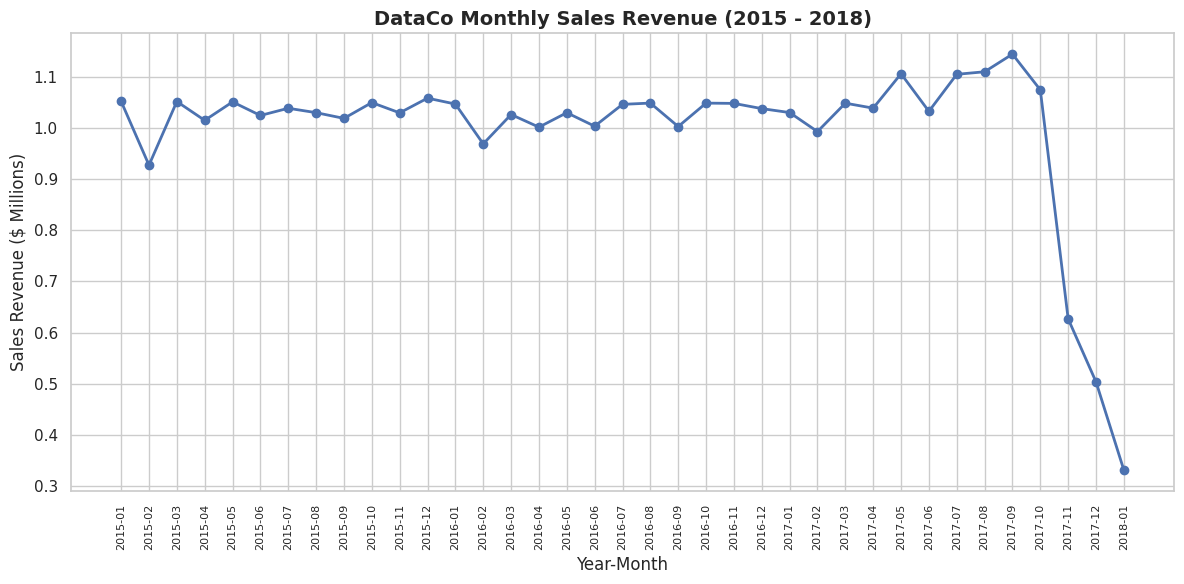

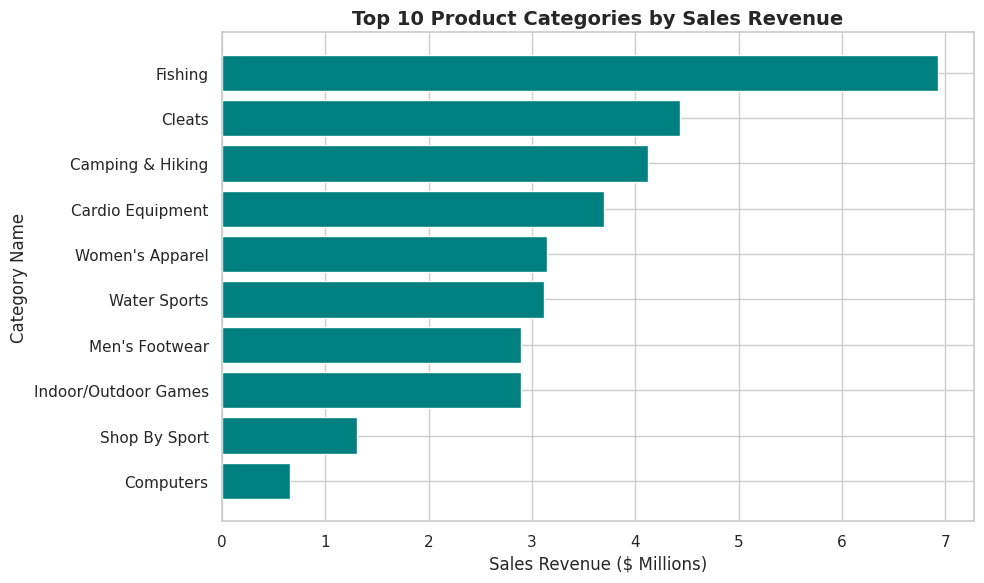


Analysis and visualizations rendered successfully!


In [24]:
# ==========================================
# OBJECTIVE 1: ANALYSE OVERALL SALES PERFORMANCE
# ==========================================

# 1. Merge datasets to establish complete transactional context
df = order_items.merge(
    orders[['Order Id', 'order date (DateOrders)', 'Order Status']],
    on='Order Id',
    how='left',
)
df = df.merge(
    products[['Product Card Id', 'Product Category Id', 'Product Name']],
    on='Product Card Id',
    how='left',
)
df = df.merge(
    categories[['Category Id', 'Category Name', 'Department Id']],
    left_on='Product Category Id',
    right_on='Category Id',
    how='left',
)
df = df.merge(departments, on='Department Id', how='left')

# Convert order date and extract temporal features
df['order_date'] = pd.to_datetime(df['order date (DateOrders)'])
df['Year'] = df['order_date'].dt.year
df['Month'] = df['order_date'].dt.month
df['YearMonth'] = df['order_date'].dt.to_period('M')

# 2. Calculate Total Sales Revenue and Order Volume
total_sales = df['Sales'].sum()
total_revenue = df['Order Item Total'].sum()
total_order_volume = df['Order Id'].nunique()
total_items_sold = df['Order Item Quantity'].sum()

print('\n' + '=' * 50)
print('OBJECTIVE 1: SALES PERFORMANCE METRICS')
print('=' * 50)
print(f'Total Gross Sales: ${total_sales:,.2f}')
print(f'Total Net Revenue (Item Total): ${total_revenue:,.2f}')
print(f'Total Order Volume (Unique Orders): {total_order_volume:,}')
print(f'Total Items Sold: {total_items_sold:,}')

# 3. Examine Yearly and Monthly Sales Trends
yearly_sales = (
    df.groupby('Year')
    .agg(
        Total_Sales=('Sales', 'sum'),
        Total_Revenue=('Order Item Total', 'sum'),
        Order_Volume=('Order Id', 'nunique'),
        Items_Sold=('Order Item Quantity', 'sum'),
    )
    .reset_index()
)

print('\n--- Yearly Sales Trends ---')
print(yearly_sales)

monthly_sales = (
    df.groupby('YearMonth')
    .agg(
        Total_Sales=('Sales', 'sum'),
        Total_Revenue=('Order Item Total', 'sum'),
        Order_Volume=('Order Id', 'nunique'),
    )
    .reset_index()
)
monthly_sales['YearMonth_str'] = monthly_sales['YearMonth'].astype(str)

# 4. Identify Top Products and Categories Contributing to Sales
top_categories = (
    df.groupby('Category Name')
    .agg(
        Total_Sales=('Sales', 'sum'),
        Order_Volume=('Order Id', 'nunique'),
        Items_Sold=('Order Item Quantity', 'sum'),
    )
    .reset_index()
    .sort_values(by='Total_Sales', ascending=False)
)

print('\n--- Top 5 Categories by Sales Revenue ---')
print(top_categories.head(5))

top_products = (
    df.groupby('Product Name')
    .agg(
        Total_Sales=('Sales', 'sum'),
        Order_Volume=('Order Id', 'nunique'),
        Items_Sold=('Order Item Quantity', 'sum'),
    )
    .reset_index()
    .sort_values(by='Total_Sales', ascending=False)
)

print('\n--- Top 5 Products by Sales Revenue ---')
print(top_products.head(5))

# ==========================================
# 5. GENERATE AND DISPLAY VISUALIZATIONS
# ==========================================

# Chart 1: Monthly Sales Trend Line Chart
plt.figure(figsize=(12, 6))
plt.plot(
    monthly_sales['YearMonth_str'],
    monthly_sales['Total_Sales'] / 1e6,
    marker='o',
    color='b',
    linewidth=2,
)
plt.title(
    'DataCo Monthly Sales Revenue (2015 - 2018)',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Year-Month', fontsize=12)
plt.ylabel('Sales Revenue ($ Millions)', fontsize=12)
plt.xticks(rotation=90, fontsize=8)
plt.tight_layout()
plt.savefig('monthly_sales_trend.png', dpi=300)
plt.show()  # Renders the visualization inline in your notebook/Colab

# Chart 2: Top 10 Product Categories Bar Chart
plt.figure(figsize=(10, 6))
top_cat_plot = top_categories.head(10).sort_values(
    by='Total_Sales', ascending=True
)
plt.barh(
    top_cat_plot['Category Name'],
    top_cat_plot['Total_Sales'] / 1e6,
    color='teal',
)
plt.title(
    'Top 10 Product Categories by Sales Revenue', fontsize=14, fontweight='bold'
)
plt.xlabel('Sales Revenue ($ Millions)', fontsize=12)
plt.ylabel('Category Name', fontsize=12)
plt.tight_layout()
plt.savefig('top_categories.png', dpi=300)
plt.show()  # Renders the visualization inline in your notebook/Colab

print('\nAnalysis and visualizations rendered successfully!')